## **Emotion Classification with RNNs, LSTMs & GRUs**

## **1. Import Basic Libraries**

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from datasets import load_dataset
import warnings
warnings.filterwarnings('ignore')

## **2. Load Dataset**
## DataSet Link On Hugging Face : https://huggingface.co/datasets/dair-ai/emotion

In [2]:
emotion_dataset = load_dataset('dair-ai/emotion')

train_text = emotion_dataset['train']['text']
train_label = emotion_dataset['train']['label']

test_text = emotion_dataset['train']['text']
test_label = emotion_dataset['train']['label']

README.md:   0%|          | 0.00/9.05k [00:00<?, ?B/s]

split/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.03MB            

split/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  127kB            

split/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  129kB            

split/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/16000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

In [3]:
label_names = emotion_dataset['train'].features['label'].names

In [4]:
label_names

['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']

In [5]:
# Add in On DataFrame
df_train = pd.DataFrame(
    {
        'text'  : train_text,
        'label' : [label_names[i] for i in train_label]
    }
)

df_test = pd.DataFrame(
    {
        'text'  : test_text,
        'label' : [label_names[i] for i in test_label]
    }
)

In [6]:
df_train

,text,label
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger
...,...,...
15995,i just had a very brief time in the beanbag an...,sadness
15996,i am now turning and i feel pathetic that i am...,sadness
15997,i feel strong and good overall,joy
15998,i feel like this was such a rude comment and i...,anger


In [7]:
df_test

,text,label
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger
...,...,...
15995,i just had a very brief time in the beanbag an...,sadness
15996,i am now turning and i feel pathetic that i am...,sadness
15997,i feel strong and good overall,joy
15998,i feel like this was such a rude comment and i...,anger


In [8]:
print('NULL Value in Train :\n', df_train.isnull().sum())
print('\nNULL Value in Test :\n', df_test.isnull().sum())

NULL Value in Train :
 text     0
label    0
dtype: int64

NULL Value in Test :
 text     0
label    0
dtype: int64


## **3. Exploratory Data Analysis (EDA)**

In [9]:
orders = df_train['label'].value_counts().index

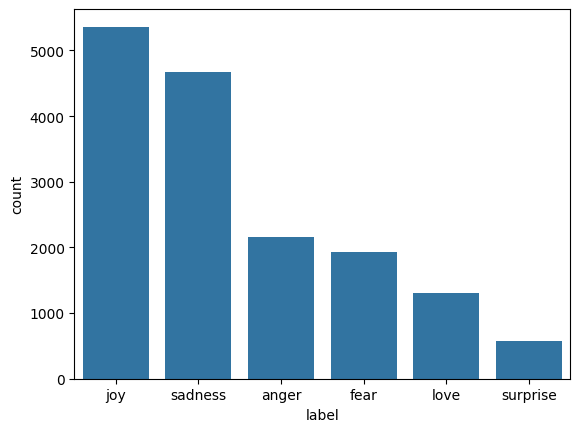

In [10]:
sns.countplot(x = 'label' , data = df_train , order= orders)
plt.show()

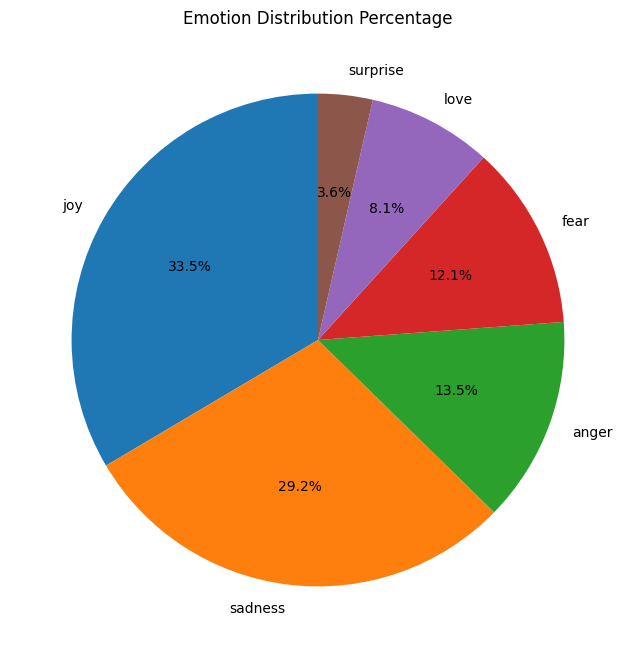

In [11]:
emotion_percentage = (df_train["label"].value_counts(normalize=True) * 100)

plt.figure(figsize=(8, 8))
plt.pie(
    emotion_percentage,
    labels=emotion_percentage.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Emotion Distribution Percentage")
plt.show()

## **😊4. Data Preprocessing - Using NLP**:

In [24]:
from os import truncate
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

max_words = 10000

tokenizer = Tokenizer(num_words= max_words , oov_token = '')
tokenizer.fit_on_texts(df_train['text'])

train_sequence = tokenizer.texts_to_sequences(df_train['text'])
test_sequence  = tokenizer.texts_to_sequences(df_test['text'])

padded_train_sequece = pad_sequences(train_sequence , maxlen = 50 , padding = 'post' , truncating = 'post')
padded_test_sequece =  pad_sequences(test_sequence , maxlen = 50 , padding = 'post' , truncating = 'post')

train_labels = np.array(train_label)
test_labels = np.array(test_label)

num_classes = len(np.unique(train_labels))

print("Num Classes : " , num_classes)
print(f"Vocabulary Sixe : {len(tokenizer.word_index)}")
print(f"Maxx Sentebce Length : {padded_train_sequece.shape[1]}")


Num Classes :  6
Vocabulary Sixe : 15213
Maxx Sentebce Length : 50



## **5. Shared Training Utilities**

In [13]:
from sklearn.utils import class_weight

class_weights = class_weight.compute_class_weight(
    class_weight = 'balanced',
    classes      = np.unique(train_labels),
    y            = train_labels
)

In [14]:
class_weight_dict = dict(enumerate(class_weights))

In [15]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor = 'val_loss',
    patience = 3,
    restore_best_weights = True
)

## **6. Phase 1 — Plain Foundational Models**


**6.1 Model 1 — Simple RNN**

In [16]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding , Dense  , SimpleRNN , LSTM , GRU , Dropout

rnn_model = Sequential([
    Embedding(input_dim = max_words , output_dim = 128 , input_length = 50),
    SimpleRNN(units = 128 , return_sequences = True),
    Dropout(0.5),
    SimpleRNN(units = 64),
    Dropout(0.5),
    Dense(units = num_classes , activation = 'softmax')
])

rnn_model.compile(
    optimizer = 'adam',
    loss = 'sparse_categorical_crossentropy',
    metrics = ['accuracy']
)

In [19]:
rnn_model.fit(
    padded_train_sequece ,
    train_labels,
    validation_data = (padded_test_sequece, test_labels),
    epochs = 20,
    batch_size = 32,
    class_weight = class_weight_dict,
    callbacks = [early_stopping]
)

rnn_loss, rnn_accuracy = rnn_model.evaluate(padded_test_sequece, test_labels)
print(f"RNN Loss: {rnn_loss}")
print(f"RNN Accuracy: {rnn_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 21s 38ms/step - accuracy: 0.1549 - loss: 2.0240 - val_accuracy: 0.1672 - val_loss: 1.7789
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 15s 31ms/step - accuracy: 0.1416 - loss: 1.8809 - val_accuracy: 0.1201 - val_loss: 1.7767
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 20s 31ms/step - accuracy: 0.1308 - loss: 1.8230 - val_accuracy: 0.1341 - val_loss: 1.8094
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 20s 30ms/step - accuracy: 0.1256 - loss: 1.8088 - val_accuracy: 0.1210 - val_loss: 1.7489
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 15s 30ms/step - accuracy: 0.1381 - loss: 1.8033 - val_accuracy: 0.0358 - val_loss: 1.8185
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 25s 38ms/step - accuracy: 0.1402 - loss: 1.8028 - val_accuracy: 0.1210 - val_loss: 1.7963
Epoch 7/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 19s 35ms/step - accuracy: 0.1506 - loss: 1.8008 - val_accuracy: 0.0358 - val_loss: 1.7939
500/500 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.1210 - loss: 1.7489
RNN Loss: 1.748


**6.2 Model 2 — Standard LSTM**

In [21]:
lstm_model = Sequential([
    Embedding(input_dim = max_words , output_dim = num_classes , input_length = 50),
    LSTM(units= 128 , return_sequences= True),
    Dropout(0.5),
    LSTM(units = 64),
    Dropout(0.5),
    Dense(units= num_classes , activation = 'softmax')
])

In [22]:
lstm_model.compile(
    optimizer = 'adam',
    loss = 'sparse_categorical_crossentropy',
    metrics = ['accuracy']
)

In [26]:
lstm_model.fit(
    padded_train_sequece,
    train_labels,
    validation_data = (padded_test_sequece , test_labels),
    epochs = 20,
    batch_size = 32,
    class_weight = class_weight_dict,
    callbacks = [early_stopping]
)

lstm_loss, lstm_accuracy = lstm_model.evaluate(padded_test_sequece, test_labels)
print(f"LSTM Loss: {lstm_loss}")
print(f"LSTM Accuracy: {lstm_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 45s 86ms/step - accuracy: 0.1616 - loss: 1.7938 - val_accuracy: 0.0358 - val_loss: 1.8001
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 47s 93ms/step - accuracy: 0.1623 - loss: 1.7930 - val_accuracy: 0.0358 - val_loss: 1.8127
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 96s 122ms/step - accuracy: 0.1436 - loss: 1.7934 - val_accuracy: 0.0816 - val_loss: 1.8060
500/500 ━━━━━━━━━━━━━━━━━━━━ 14s 29ms/step - accuracy: 0.0358 - loss: 1.8001
LSTM Loss: 1.8000980615615845
LSTM Accuracy: 0.035750001668930054


**6.3 Model 3 — Standard GRU**

In [29]:
gru_model = Sequential([
    Embedding(input_dim = max_words, output_dim = 128 , input_length = 50),
    GRU(units=128, return_sequences=True),
    Dropout(0.5),
    GRU(units=64),
    Dropout(0.5),
    Dense(units=num_classes, activation='softmax') #Output Layer
])


In [30]:
gru_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
    )

In [31]:
gru_model.fit(
    padded_train_sequece,
    train_labels,
    validation_data=(padded_test_sequece, test_labels),
    epochs = 20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

gru_loss, gru_accuracy = gru_model.evaluate(padded_test_sequece, test_labels)
print(f"GRU Loss: {gru_loss}")
print(f"GRU Accuracy: {gru_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 44s 83ms/step - accuracy: 0.1528 - loss: 1.7964 - val_accuracy: 0.0364 - val_loss: 1.8278
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 47s 94ms/step - accuracy: 0.1406 - loss: 1.7957 - val_accuracy: 0.1376 - val_loss: 1.7941
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 39s 77ms/step - accuracy: 0.1408 - loss: 1.7941 - val_accuracy: 0.1343 - val_loss: 1.7793
500/500 ━━━━━━━━━━━━━━━━━━━━ 8s 15ms/step - accuracy: 0.0364 - loss: 1.8278
GRU Loss: 1.8277753591537476
GRU Accuracy: 0.036375001072883606


In [32]:
result_df = pd.DataFrame({
    'Model' : ['RNN', 'LSTM', 'GRU'],
    'Test Loss': [rnn_loss, lstm_loss, gru_loss],
    'Test Accuracy': [rnn_accuracy, lstm_accuracy, gru_accuracy]
    }).sort_values(by='Test Accuracy',ascending=False)
result_df


,Model,Test Loss,Test Accuracy
0,RNN,1.748878,0.121000
2,GRU,1.827775,0.036375
1,LSTM,1.800098,0.035750


## **7. Phase 2 — Advanced Bidirectional GRU**

**7.1 Model 4 — Advanced Stacked Bidirectional GRU**

In [20]:
from tensorflow.keras.layers import Bidirectional

BiGRU = Sequential([
    Embedding(input_dim = max_words , output_dim = 300 , input_length = 50),
    Bidirectional(GRU(128 , return_sequences = True)),
    Dropout(0.5),
    Bidirectional(GRU(64)),
    Dropout(0.5),
    Dense(num_classes , activation = 'softmax')

])

In [27]:
BiGRU.compile(
    optimizer = 'adam',
    loss = 'sparse_categorical_crossentropy',
    metrics = ['accuracy']
)

In [28]:
BiGRU.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [34]:
BiGRU.fit(
    padded_train_sequece,
    train_labels,
    validation_data = (padded_test_sequece , test_labels),
    epochs = 20 ,
    batch_size = 32,
    class_weight = class_weight_dict,
    callbacks = [early_stopping]
    )

BiGRU_loss , BiGRU_accuracy = BiGRU.evaluate(padded_test_sequece , test_labels)
print(f"BiGRU Loss: {BiGRU_loss}")
print(f"BiGRU Accuracy: {BiGRU_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 168s 329ms/step - accuracy: 0.5346 - loss: 1.1089 - val_accuracy: 0.9247 - val_loss: 0.2280
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 157s 240ms/step - accuracy: 0.9228 - loss: 0.2228 - val_accuracy: 0.9464 - val_loss: 0.1361
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 102s 203ms/step - accuracy: 0.9433 - loss: 0.1513 - val_accuracy: 0.9609 - val_loss: 0.1010
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 101s 202ms/step - accuracy: 0.9597 - loss: 0.1074 - val_accuracy: 0.9724 - val_loss: 0.0658
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 99s 198ms/step - accuracy: 0.9668 - loss: 0.0857 - val_accuracy: 0.9765 - val_loss: 0.0662
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 144s 202ms/step - accuracy: 0.9739 - loss: 0.0740 - val_accuracy: 0.9813 - val_loss: 0.0513
Epoch 7/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 99s 198ms/step - accuracy: 0.9807 - loss: 0.0542 - val_accuracy: 0.9904 - val_loss: 0.0280
Epoch 8/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 102s 204ms/step - accuracy: 0.9821 - l

## **8. Overall Evaluation & Bias Analysis**

**8.1 Final Model Confusion Matrices (Raw Counts & Normalized %)**


500/500 ━━━━━━━━━━━━━━━━━━━━ 32s 63ms/step


<Axes: >

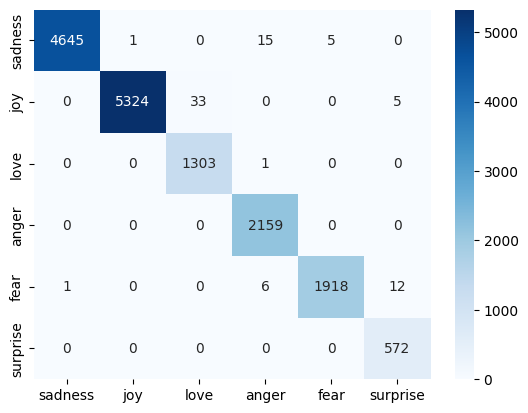

In [35]:
from sklearn.metrics import confusion_matrix

BiGRU_predictions = np.argmax(BiGRU.predict(padded_test_sequece) , axis = 1)
sns.heatmap(confusion_matrix(test_label , BiGRU_predictions) , annot = True , fmt = 'd' , cmap='Blues', xticklabels=label_names, yticklabels=label_names)

## **9. Final Predictions**

In [39]:
sample_texts = [
    "I can't believe how happy I am right now, this is amazing!",
    "I feel so alone and hopeless today.",
    "I am furious that they cancelled the trip at the last minute.",
    "I feel terrified when walking down dark alleyways alone.",
    "I was shocked and completely surprised by the unexpected gift!"
]

sample_sequences = tokenizer.texts_to_sequences(sample_texts)
sample_padded_sequences = pad_sequences(sample_sequences , maxlen = 50 , padding = 'post' , truncating = 'post')

sample_predictions = np.argmax(BiGRU.predict(sample_padded_sequences) , axis = 1)

for i in range(len(sample_texts)):
  print(f"Text : {sample_texts[i]}\nPredicted Emotions : {label_names[sample_predictions[i]]}" )

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
Text : I can't believe how happy I am right now, this is amazing!
Predicted Emotions : surprise
Text : I feel so alone and hopeless today.
Predicted Emotions : sadness
Text : I am furious that they cancelled the trip at the last minute.
Predicted Emotions : anger
Text : I feel terrified when walking down dark alleyways alone.
Predicted Emotions : fear
Text : I was shocked and completely surprised by the unexpected gift!
Predicted Emotions : surprise



## **10. Save Model & Tokenizer**

In [44]:
import os
import pickle

#making folder
model_dir = 'Artifacts'
os.makedirs(model_dir , exist_ok= True)

#Save BiGRU modle
BiGRU.save(os.path.join(model_dir , 'BiGRU_Model.keras'))

#save tokenizer
with open(os.path.join(model_dir , 'tokenizer.pkl') , 'wb') as file:
  pickle.dump(tokenizer , file)